# 03 · Đánh giá điều kiện cảnh báo ngập

Chạy `app.ai.evaluation.risk_eval` giống `scripts/evaluate_risk.py`: so điều kiện độ sâu ước tính ≥ 20 cm (triều lệch 4 giờ + mưa) với các sự kiện ngập báo chí theo cặp (quận, ngày). Chỉ **đọc** CSDL.

**Lưu ý:** nhãn âm là giả định (không có tin báo = không ngập), nên precision bị đánh giá thấp; đọc F1 và recall.

In [1]:
import os, sys
from pathlib import Path
os.environ.setdefault("PYTHONUTF8", "1")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
BACKEND = ROOT / "backend"
sys.path.insert(0, str(BACKEND))
os.chdir(BACKEND)  # để đọc backend/.env
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline

In [2]:
from app.ai.evaluation.risk_eval import evaluate, load_inputs
from app.core.database import SessionLocal
with SessionLocal() as db:
    res = evaluate(**load_inputs(db))
print(res["note"]); print("Sự kiện bỏ qua vì thiếu quận:", res["skipped_null_area_events"])

Nhãn âm là GIẢ ĐỊNH (không có tin báo chí = không ngập): precision bị đánh giá thấp, accuracy bị ngày âm chi phối, đọc F1. Triều và mưa là dữ liệu mô hình Open-Meteo, không phải trạm đo; chỉ đánh giá điều kiện độ sâu ước tính >= 20 cm, không phải toàn bộ rule engine (điểm số, xác suất, hysteresis, báo cáo, camera). Tập held-out gồm các đợt triều cường sát ngày hiệu chỉnh (2026-10-11, 2026-10-26). Baseline quy tắc cũ báo cả 24 quận nên một phần cải thiện đến từ việc giới hạn theo quận.
Sự kiện bỏ qua vì thiếu quận: 2


## Bảng chỉ số theo nhóm

In [3]:
groups = {k: v for k, v in res.items() if isinstance(v, dict)}
tbl = pd.DataFrame(groups).T[["n", "positives", "accuracy", "precision", "recall", "f1", "tp", "fp", "fn", "tn"]]
display(tbl.round(3))

,n,positives,accuracy,precision,recall,f1,tp,fp,fn,tn
held_out/ALL/district-day,10368.0,39.0,0.938,0.025,0.410,0.047,16.0,624.0,23.0,9705.0
held_out/ALL/city-day,432.0,21.0,0.852,0.136,0.381,0.200,8.0,51.0,13.0,360.0
held_out/TIDE/district-day,10368.0,19.0,0.940,0.025,0.842,0.049,16.0,622.0,3.0,9727.0
held_out/TIDE/city-day,432.0,10.0,0.880,0.138,0.800,0.235,8.0,50.0,2.0,372.0
held_out/RAIN/district-day,10368.0,25.0,0.997,0.000,0.000,0.000,0.0,2.0,25.0,10341.0
held_out/RAIN/city-day,432.0,15.0,0.963,0.000,0.000,0.000,0.0,1.0,15.0,416.0
held_out/old_rule_vs_ALL/district-day,10368.0,39.0,0.630,0.006,0.615,0.012,24.0,3816.0,15.0,6513.0
held_out/old_rule_vs_TIDE/district-day,10368.0,19.0,0.631,0.005,1.000,0.010,19.0,3821.0,0.0,6528.0
calibration/ALL/district-day,72.0,4.0,0.597,0.121,1.000,0.216,4.0,29.0,0.0,39.0
calibration/ALL/city-day,3.0,2.0,0.667,0.667,1.000,0.800,2.0,1.0,0.0,0.0


## Ma trận nhầm lẫn

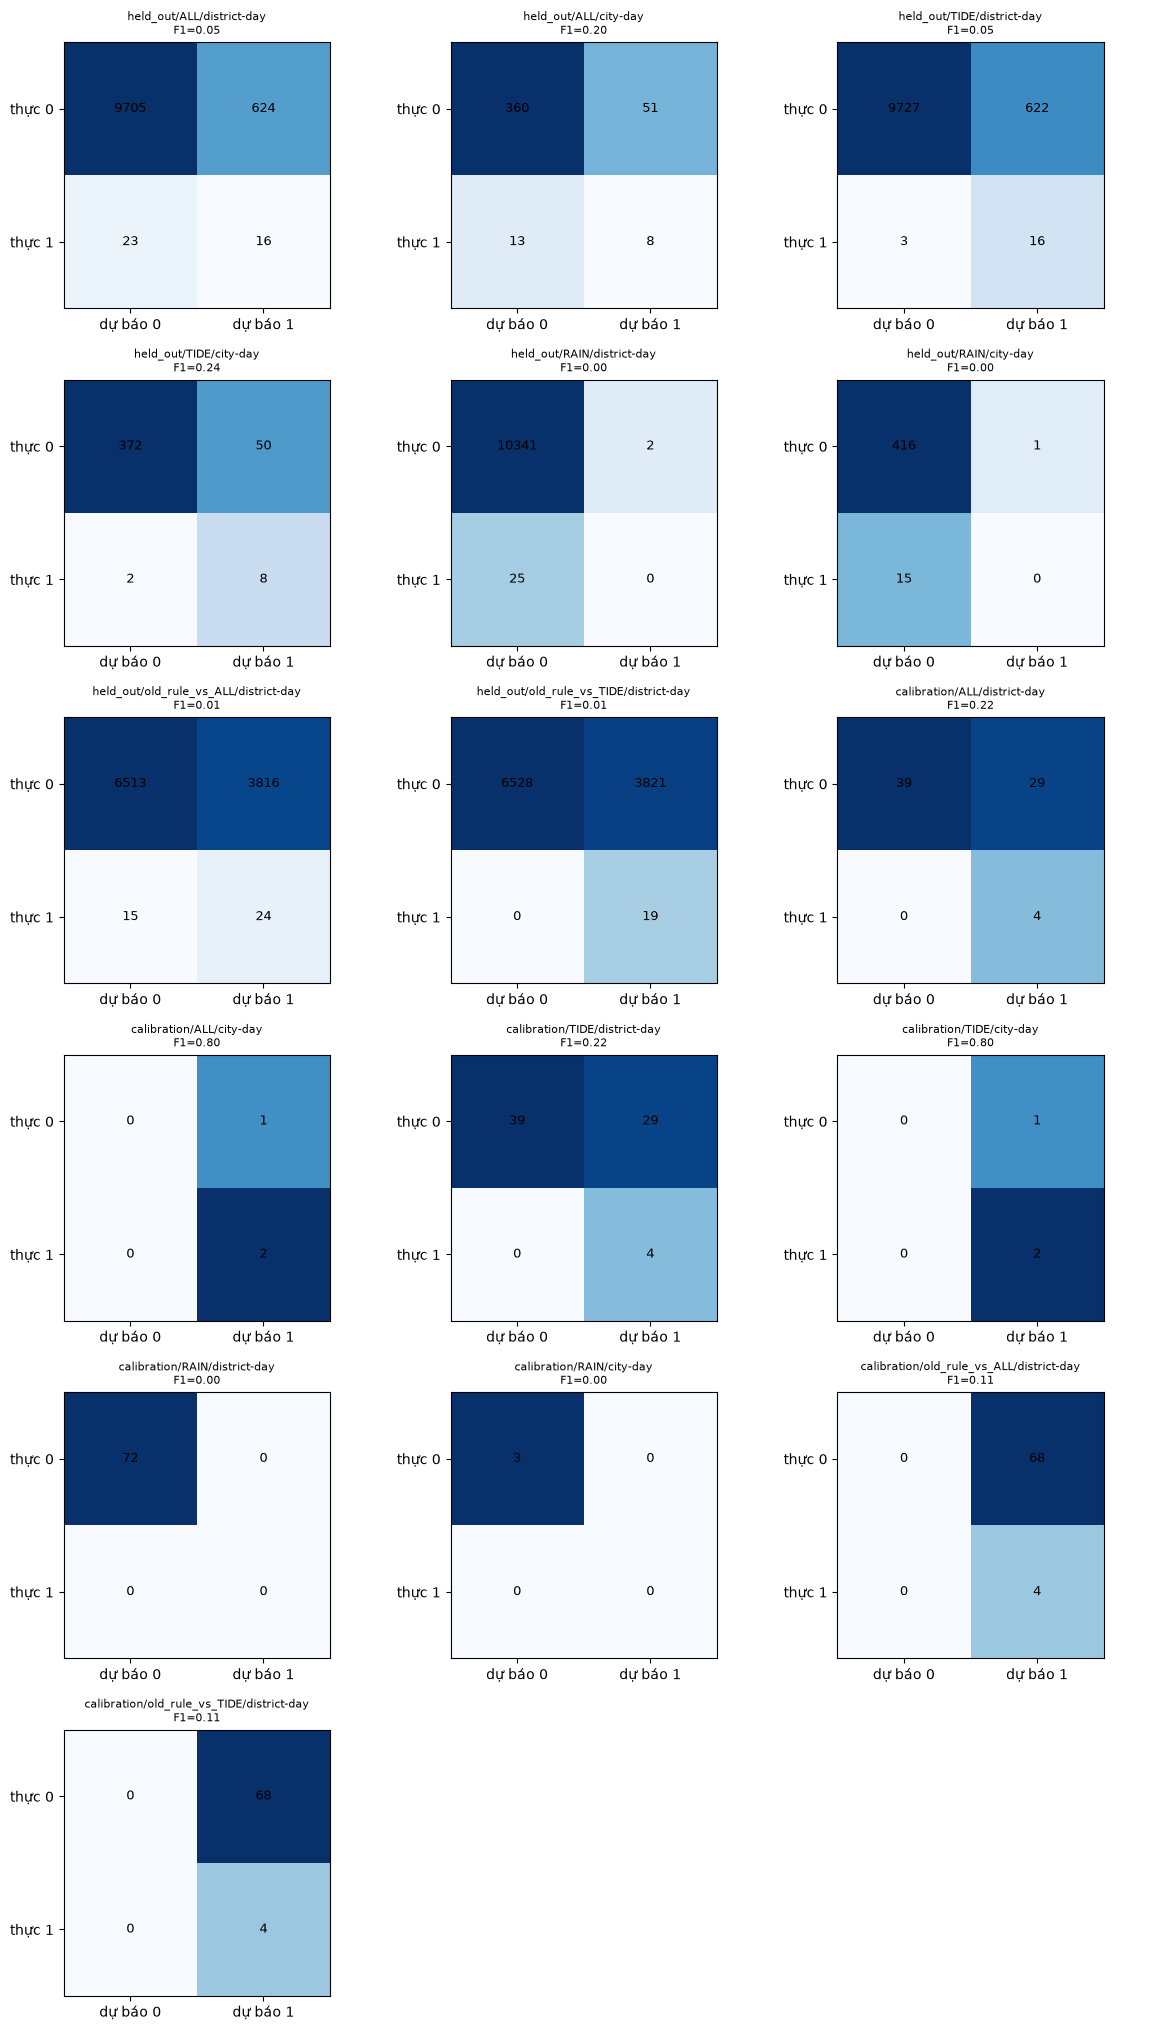

In [4]:
n = len(groups); cols = min(3, n); rows_ = -(-n // cols)
fig, axes = plt.subplots(rows_, cols, figsize=(4 * cols, 3.4 * rows_), squeeze=False)
for ax, (k, v) in zip(axes.ravel(), groups.items()):
    cm = np.array([[v["tn"], v["fp"]], [v["fn"], v["tp"]]])
    ax.imshow(np.log1p(cm), cmap="Blues")
    for (i, j), x in np.ndenumerate(cm): ax.text(j, i, int(x), ha="center", va="center", fontsize=9)
    ax.set(title=f"{k}\nF1={v['f1']:.2f}", xticks=[0, 1], yticks=[0, 1], xticklabels=["dự báo 0", "dự báo 1"], yticklabels=["thực 0", "thực 1"])
    ax.title.set_fontsize(8)
for ax in axes.ravel()[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

**Nhận xét.** Tập kiểm chứng nhỏ, nhãn từ báo chí không đầy đủ, nên chỉ số mang tính tham khảo. Giới hạn đầy đủ nằm trong `docs/ai-methodology.md` và `docs/known-limitations.md`.